In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("train.csv")

print(df.shape)
display(df.head())

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Liczba kolumn według typu danych:
object     43
int64      35
float64     3
Name: count, dtype: int64

Statystyki opisowe dla kluczowych kolumn:


,SalePrice,GrLivArea,LotArea,OverallQual,YearBuilt,TotalBsmtSF
count,1460.0,1460.00,1460.00,1460.00,1460.00,1460.00
mean,180921.2,1515.46,10516.83,6.10,1971.27,1057.43
std,79442.5,525.48,9981.26,1.38,30.20,438.71
min,34900.0,334.00,1300.00,1.00,1872.00,0.00
25%,129975.0,1129.50,7553.50,5.00,1954.00,795.75
50%,163000.0,1464.00,9478.50,6.00,1973.00,991.50
75%,214000.0,1776.75,11601.50,7.00,2000.00,1298.25
max,755000.0,5642.00,215245.00,10.00,2010.00,6110.00



Kolumny z wartościami NaN:


,Liczba braków,(%)
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


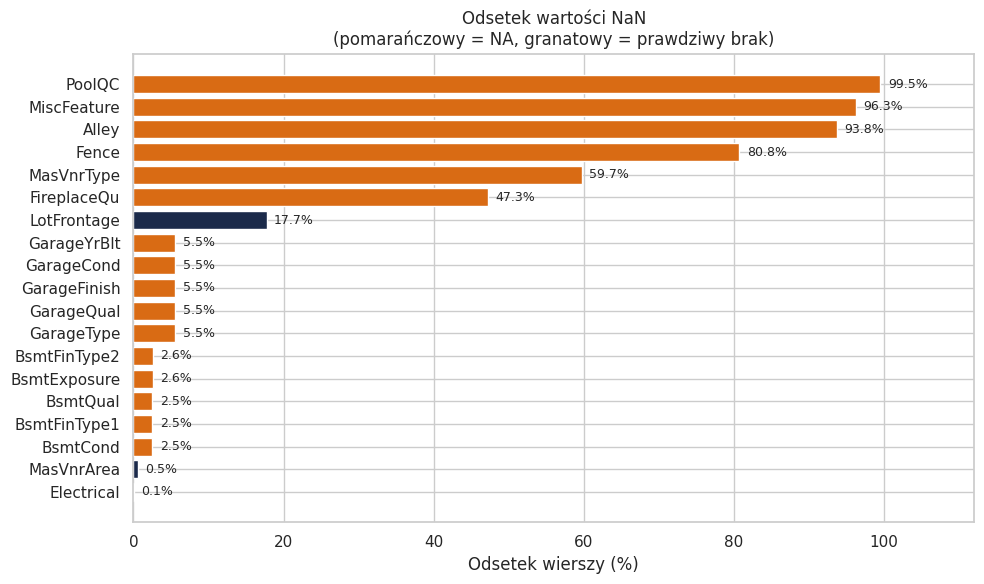

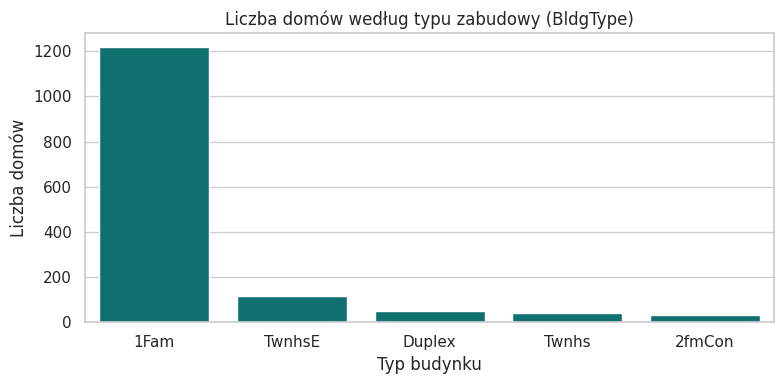

In [ ]:
print("Liczba kolumn według typu danych:")
print(df.dtypes.value_counts())
print("\nStatystyki opisowe dla kluczowych kolumn:")
kluczowe = ["SalePrice", "GrLivArea", "LotArea", "OverallQual", "YearBuilt", "TotalBsmtSF"]
display(df[kluczowe].describe().round(2))

braki = df.isna().sum()
braki_procent = (df.isna().mean() * 100).round(1)

tabela_brakow = pd.DataFrame({
    "Liczba braków": braki[braki > 0],
    "(%)": braki_procent[braki > 0]
}).sort_values(by="Liczba braków", ascending=False)

print("\nKolumny z wartościami NaN:")
display(tabela_brakow)

braki_pct = (df.isna().mean() * 100)
braki_pct = braki_pct[braki_pct > 0].sort_values(ascending=True)

prawdziwe_braki = ["LotFrontage", "MasVnrArea", "Electrical"]
kolory = ["#1b2a4a" if col in prawdziwe_braki else "#d96b14" for col in braki_pct.index]

plt.figure(figsize=(10, 6))
bars = plt.barh(braki_pct.index, braki_pct.values, color=kolory)

for bar in bars:
    val = bar.get_width()
    plt.text(val + 1, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center", fontsize=9)

plt.xlim(0, 112)
plt.xlabel("Odsetek wierszy (%)")
plt.title("Odsetek wartości NaN\n(pomarańczowy = NA, granatowy = prawdziwy brak)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="BldgType", order=df["BldgType"].value_counts().index, color="teal")
plt.title("Liczba domów według typu zabudowy (BldgType)")
plt.xlabel("Typ budynku")
plt.ylabel("Liczba domów")
plt.tight_layout()
plt.show()

Zmienna docelowa to SalePrice - ostateczna cena sprzedaży domu w USD.

Minimum: 34,900 USD
Maksimum: 755,000 USD
Średnia: 180,921 USD
Mediana: 163,000 USD
Q1 (25%): 129,975 USD
Q3 (75%): 214,000 USD
IQR: 84,025 USD


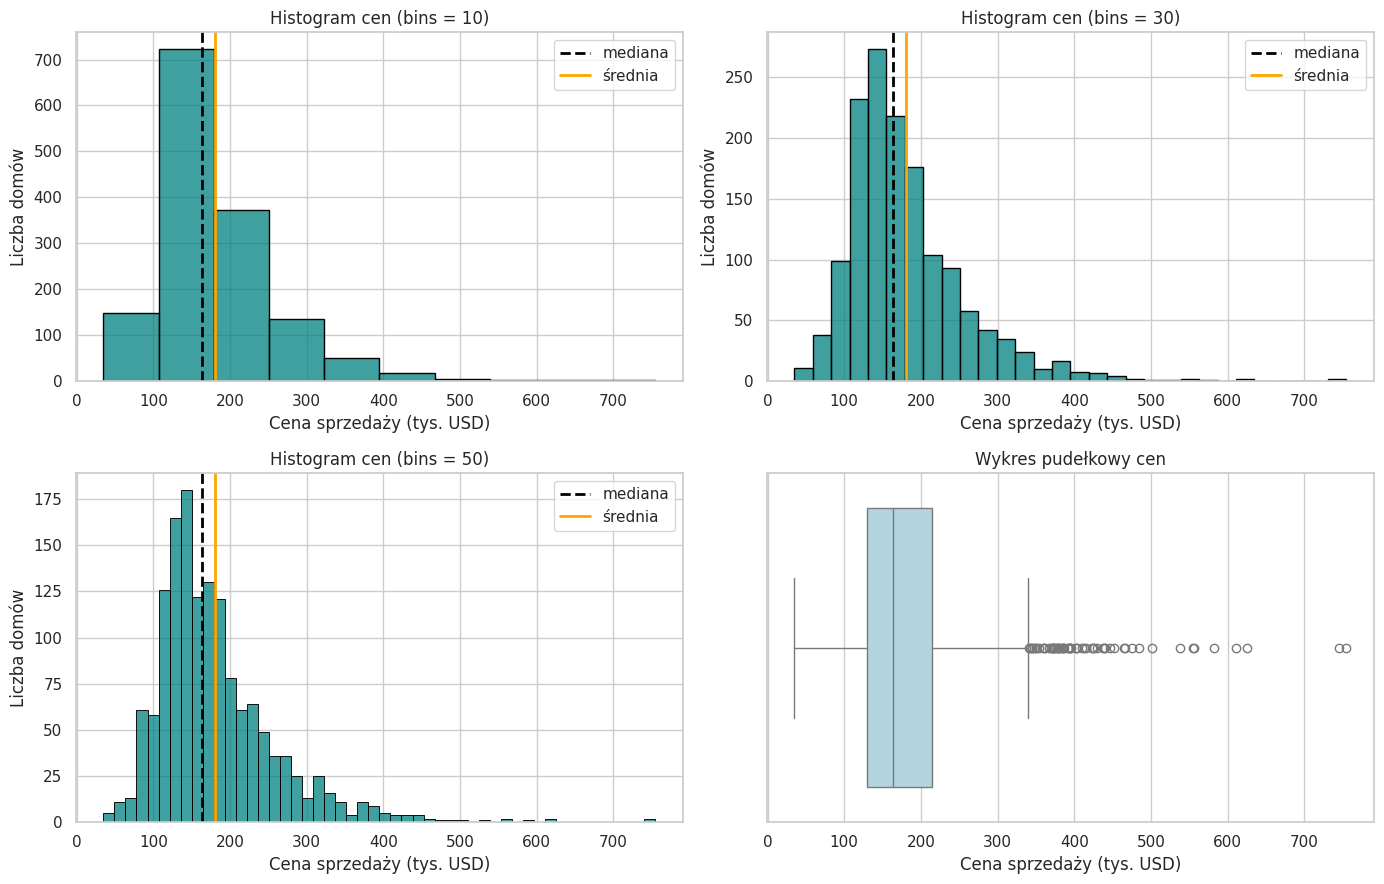

In [ ]:
cena = df["SalePrice"]

q1 = cena.quantile(0.25)
q3 = cena.quantile(0.75)
iqr = q3 - q1

print(f"Minimum: {cena.min():,.0f} USD")
print(f"Maksimum: {cena.max():,.0f} USD")
print(f"Średnia: {cena.mean():,.0f} USD")
print(f"Mediana: {cena.median():,.0f} USD")
print(f"Q1 (25%): {q1:,.0f} USD")
print(f"Q3 (75%): {q3:,.0f} USD")
print(f"IQR: {iqr:,.0f} USD")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, b in zip([axes[0, 0], axes[0, 1], axes[1, 0]], [10, 30, 50]):
    sns.histplot(cena / 1000, bins=b, ax=ax, color="teal", edgecolor="black")
    ax.axvline(cena.median() / 1000, color="black", linestyle="--", linewidth=2, label="mediana")
    ax.axvline(cena.mean() / 1000, color="orange", linestyle="-", linewidth=2, label="średnia")
    ax.set_title(f"Histogram cen (bins = {b})")
    ax.set_xlabel("Cena sprzedaży (tys. USD)")
    ax.set_ylabel("Liczba domów")
    ax.legend()

sns.boxplot(x=cena / 1000, ax=axes[1, 1], color="lightblue")
axes[1, 1].set_title("Wykres pudełkowy cen")
axes[1, 1].set_xlabel("Cena sprzedaży (tys. USD)")

plt.tight_layout()
plt.show()

Rozkład cen jest widoczny w kodzie powyżej. Rozkład nie jest normalny, ponieważ histogram nie jest symetryczny, jest prawostronnie skośny, większość cen skupia się w przedziale 100-200 tys. USD, a w prawo ciągnie się ogon. Średnia jest wyższa od mediany. Widać liczne wartości odstające, ale to zazwyczaj luksusowe domy.

14 kolumn związanych z powierzchnią:
['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']

Korelacja z SalePrice (od najsilniejszej):
SalePrice       1.000
GrLivArea       0.709
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
MasVnrArea      0.477
BsmtFinSF1      0.386
WoodDeckSF      0.324
2ndFlrSF        0.319
OpenPorchSF     0.316
LotArea         0.264
BsmtUnfSF       0.214
PoolArea        0.092
BsmtFinSF2     -0.011
LowQualFinSF   -0.026
Name: SalePrice, dtype: float64


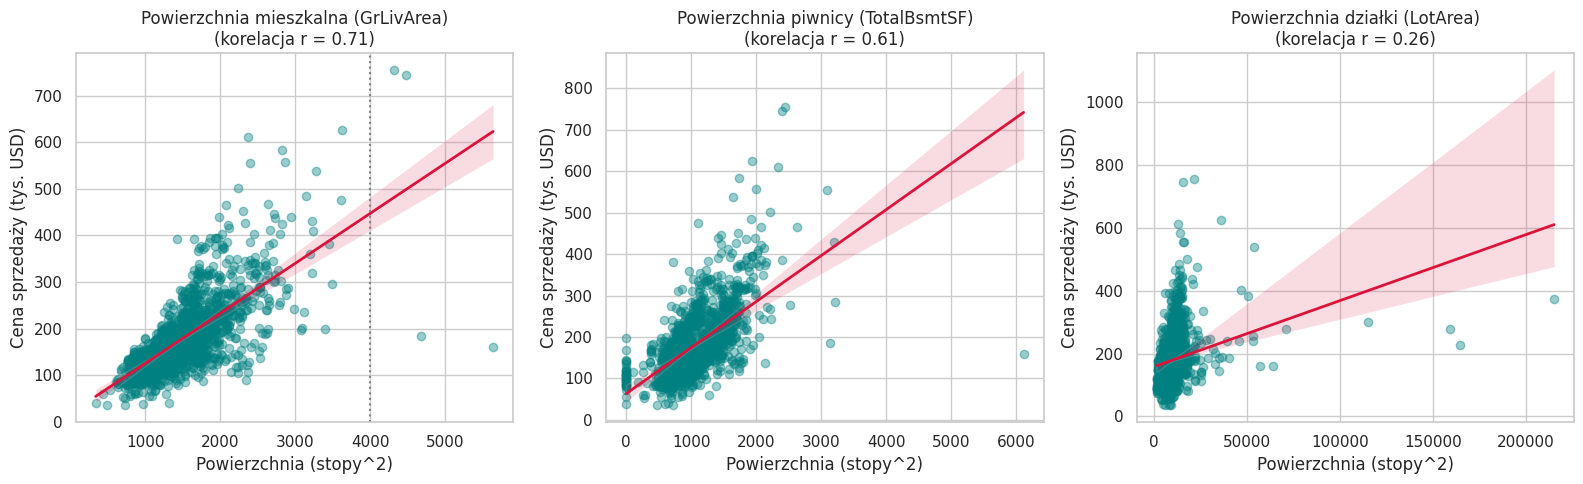


Domy o powierzchni mieszkalnej powyżej 4000 stóp^2:


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
691,692,4316,755000,10,Normal
1182,1183,4476,745000,10,Abnorml
1298,1299,5642,160000,10,Partial


In [ ]:
# H: "WIĘKSZE DOMY SĄ DROŻSZE"

kolumny_pow = [col for col in df.columns if "Area" in col or "SF" in col]
print(f"{len(kolumny_pow)} kolumn związanych z powierzchnią:")
print(kolumny_pow)

korelacje = df[kolumny_pow + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False)
print("\nKorelacja z SalePrice (od najsilniejszej):")
print(korelacje.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cechy = [
    ("GrLivArea", "Powierzchnia mieszkalna (GrLivArea)"),
    ("TotalBsmtSF", "Powierzchnia piwnicy (TotalBsmtSF)"),
    ("LotArea", "Powierzchnia działki (LotArea)")
]

for ax, (col, tytul) in zip(axes, cechy):
    r = df[col].corr(df["SalePrice"])
    sns.regplot(data=df, x=col, y=df["SalePrice"] / 1000, ax=ax, scatter_kws={"alpha": 0.4, "color": "teal"}, line_kws={"color": "crimson", "linewidth": 2})
    ax.set_title(f"{tytul}\n(korelacja r = {r:.2f})")
    ax.set_xlabel("Powierzchnia (stopy^2)")
    ax.set_ylabel("Cena sprzedaży (tys. USD)")

axes[0].axvline(4000, color="gray", linestyle=":")
plt.tight_layout()
plt.show()

print("\nDomy o powierzchni mieszkalnej powyżej 4000 stóp^2:")
display(df[df["GrLivArea"] > 4000][["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]])

Hipoteza jest prawdziwa, współczynnik korelacji jest zawsze (w naszych przypadkach) dodatni, a zależność jest w przybliżeniu liniowa, ale dla większych domów jest większy rozrzut cen. Są dziwne obserwacje, ponieważ na prawo od przerywanej linii (4000 stóp^2) widać 4 ogromne domy, wszystkie o najwyższej jakości 10. Dwa z nich osiągnęły najwyższe ceny sprzedaży w tym zbiorze (ID = 692 i ID = 1183), a dwa pozostałe zostały sprzedane zaskakująco tanio (ID = 524 i ID = 1299), ale są to częściowo niedokończone domy (Partial), więc to może być przyczyną. Powierzchnia działki ma słabszy wpływ na cenę (r = 0,26), na 3. wykresie widać, że prawie wszystkie domy skupiają się przy lewej krawędzi, a tylko widnieje kilka wyjątków. Najsilniejszy związek z ceną ma powierzchnia mieszkalna (GrLivArena).